## Problem Statement

### Business Context

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

### Objective

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications. This was a nine percent increase in the overall number of processed applications from the previous year. The process of reviewing every case is becoming a tedious task as the number of applicants is increasing every year.

The increasing number of applicants every year calls for a Machine Learning based solution that can help in shortlisting the candidates having higher chances of VISA approval. OFLC has hired the firm EasyVisa for data-driven solutions. You as a data  scientist at EasyVisa have to analyze the data provided and, with the help of a classification model:

* Facilitate the process of visa approvals.
* Recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.

### Data Description

The data contains the different attributes of employee and the employer. The detailed data dictionary is given below.

* case_id: ID of each visa application
* continent: Information of continent the employee
* education_of_employee: Information of education of the employee
* has_job_experience: Does the employee has any job experience? Y= Yes; N = No
* requires_job_training: Does the employee require any job training? Y = Yes; N = No
* no_of_employees: Number of employees in the employer's company
* yr_of_estab: Year in which the employer's company was established
* region_of_employment: Information of foreign worker's intended region of employment in the US.
* prevailing_wage:  Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
* unit_of_wage: Unit of prevailing wage. Values include Hour, Week, Month and Year.
* full_time_position: Is the position of work full-time? Y = Full Time Position; N = Part Time Position
* case_status:  Flag indicating if the Visa was certified or denied

## Importing the necessary libraries

In [1]:
# Required packages (no pinned versions needed):
#   pip install numpy pandas matplotlib seaborn scikit-learn imbalanced-learn xgboost
# Run this notebook from the folder that contains EasyVisa.csv.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda x: "%.3f" % x)

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import (
    BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    f1_score, accuracy_score, recall_score, precision_score, roc_auc_score, ConfusionMatrixDisplay,
    confusion_matrix,
)
from xgboost import XGBClassifier

# Resampling. The imblearn Pipeline applies resampling only to the training part of each CV fold.
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

RANDOM_STATE = 1

## Import Dataset

In [2]:
EasyVisaData = pd.read_csv("EasyVisa.csv")
df = EasyVisaData.copy()

## Overview of the Dataset

#### View the first 5 rows of the dataset

In [3]:
df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.203,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.650,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.860,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.030,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.390,Year,Y,Certified


#### Shape and data types

In [4]:
print(df.shape)
df.info()

(25480, 12)
<class 'pandas.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  str    
 1   continent              25480 non-null  str    
 2   education_of_employee  25480 non-null  str    
 3   has_job_experience     25480 non-null  str    
 4   requires_job_training  25480 non-null  str    
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  str    
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  str    
 10  full_time_position     25480 non-null  str    
 11  case_status            25480 non-null  str    
dtypes: float64(1), int64(2), str(9)
memory usage: 2.3 MB


The data has 25,480 rows and 12 columns, with no missing values. Three columns are numeric (`no_of_employees`, `yr_of_estab`, `prevailing_wage`) and the rest are text.

In [5]:
# case_id is a unique identifier with no predictive meaning
print("case_id unique:", df["case_id"].is_unique)
print("duplicate rows (ignoring case_id):", df.drop(columns="case_id").duplicated().sum())
df = df.drop(columns=["case_id"])

case_id unique: True
duplicate rows (ignoring case_id): 0


`case_id` is dropped because it only identifies the row.

## Exploratory Data Analysis (EDA)

#### Statistical summary

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
no_of_employees,25480.000,5667.043,22877.929,-26.000,1022.000,2109.000,3504.000,602069.000
yr_of_estab,25480.000,1979.410,42.367,1800.000,1976.000,1997.000,2005.000,2016.000
prevailing_wage,25480.000,74455.815,52815.942,2.137,34015.480,70308.210,107735.513,319210.270


`no_of_employees` has a negative minimum (-26), which is impossible and is investigated below. `yr_of_estab` starts at 1800, which is old but possible for a company.

#### Fixing the negative values in `no_of_employees`

In [7]:
negative_rows = df[df["no_of_employees"] <= 0]
print(f"Rows with a non-positive number of employees: {len(negative_rows)} ({len(negative_rows) / len(df):.2%} of the data)")
print("Values:", sorted(negative_rows["no_of_employees"].unique()))
print(f"Smallest positive value: {df.loc[df['no_of_employees'] > 0, 'no_of_employees'].min()}")

Rows with a non-positive number of employees: 33 (0.13% of the data)
Values: [np.int64(-26), np.int64(-25), np.int64(-17), np.int64(-14), np.int64(-11)]
Smallest positive value: 12


There are 33 rows with a negative number of employees. All of them lie between -11 and -26, which is the same range as the smallest valid companies (12 to 26 employees), so they are probably sign errors. Because they are only 0.13% of the data, they are **dropped** instead of guessed at (taking the absolute value would be the alternative, and would not change the conclusions).

In [8]:
df = df[df["no_of_employees"] > 0].reset_index(drop=True)
print("Rows remaining:", len(df))
df.describe().T

Rows remaining: 25447


,count,mean,std,min,25%,50%,75%,max
no_of_employees,25447.000,5674.415,22891.842,12.000,1025.000,2112.000,3506.500,602069.000
yr_of_estab,25447.000,1979.395,42.386,1800.000,1976.000,1997.000,2005.000,2016.000
prevailing_wage,25447.000,74468.281,52822.177,2.137,34039.210,70312.500,107739.505,319210.270


With the invalid rows removed there are 25,447 records, and the smallest company has 12 employees.

In [9]:
# Proportion of each category in the categorical variables
for column in df.select_dtypes(exclude=np.number).columns:
    print(df[column].value_counts(normalize=True))
    print("-" * 50)

continent
Asia            0.662
Europe          0.146
North America   0.129
South America   0.033
Africa          0.022
Oceania         0.008
Name: proportion, dtype: float64
--------------------------------------------------
education_of_employee
Bachelor's    0.402
Master's      0.378
High School   0.134
Doctorate     0.086
Name: proportion, dtype: float64
--------------------------------------------------
has_job_experience
Y   0.581
N   0.419
Name: proportion, dtype: float64
--------------------------------------------------
requires_job_training
N   0.884
Y   0.116
Name: proportion, dtype: float64
--------------------------------------------------
region_of_employment
Northeast   0.283
South       0.275
West        0.258
Midwest     0.169
Island      0.015
Name: proportion, dtype: float64
--------------------------------------------------
unit_of_wage
Year    0.901
Hour    0.085
Week    0.011
Month   0.003
Name: proportion, dtype: float64
------------------------------------------

- About 67% of cases are certified and 33% denied. A model that certifies every case would be 66.8% accurate.
- Two thirds of applicants are from Asia, and about 80% have a Bachelor's or Master's degree.
- 90% of the wages are quoted per year, 8.5% per hour.

### Univariate Analysis

In [10]:
def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None, log_x=False):
    """Boxplot (top) and histogram (bottom) with the mean (green) and median (black) marked."""
    f2, (ax_box, ax_hist) = plt.subplots(
        nrows=2, sharex=True, gridspec_kw={"height_ratios": (0.25, 0.75)}, figsize=figsize,
    )
    sns.boxplot(data=data, x=feature, ax=ax_box, showmeans=True, color="violet")
    sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist, bins=bins if bins else "auto", log_scale=False)
    ax_hist.axvline(data[feature].mean(), color="green", linestyle="--", label="mean")
    ax_hist.axvline(data[feature].median(), color="black", linestyle="-", label="median")
    ax_hist.legend()
    if log_x:
        ax_box.set_xscale("log")
        ax_hist.set_xscale("log")
    plt.show()

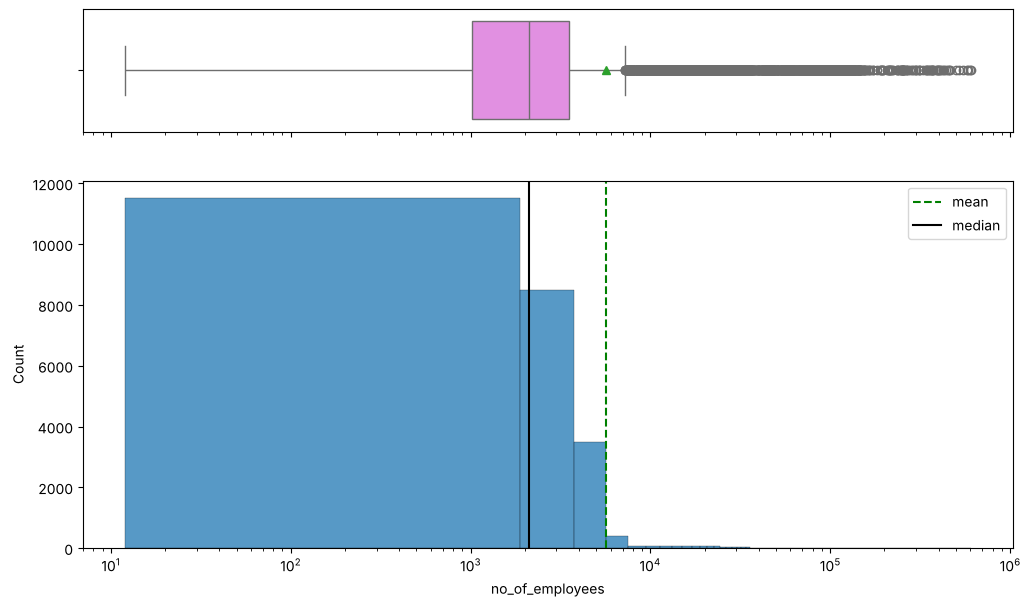

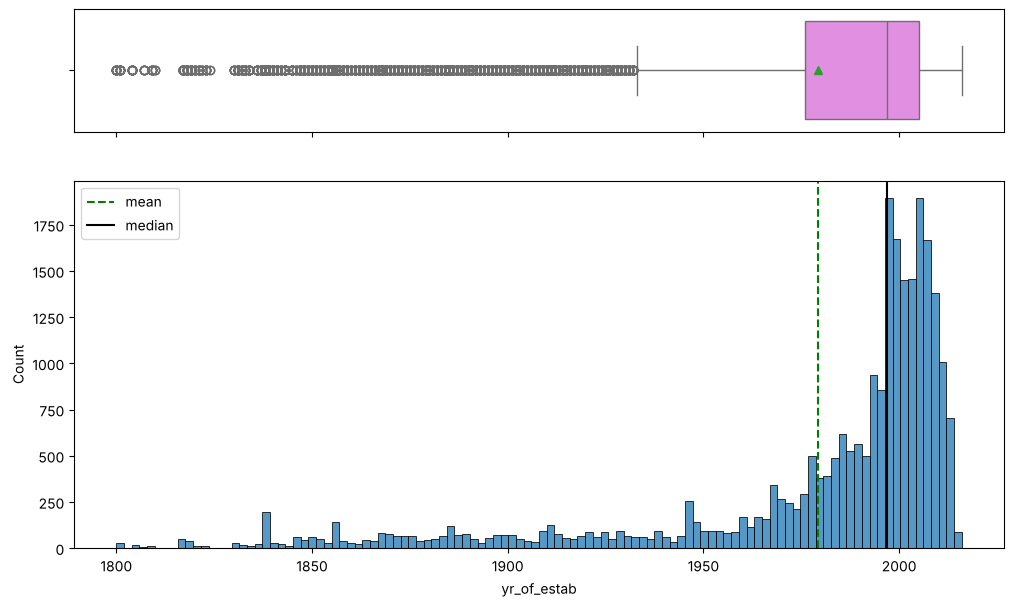

In [11]:
histogram_boxplot(df, "no_of_employees", log_x=True)
histogram_boxplot(df, "yr_of_estab")

- `no_of_employees` is extremely right-skewed, so it is plotted on a log scale. The median company has about 2,100 employees, only about a quarter of companies have fewer than 1,000, and a few have several hundred thousand.
- `yr_of_estab` is left-skewed: most companies were founded after 1975, with a long tail of old companies back to 1800.

#### `prevailing_wage` and its unit

`prevailing_wage` is quoted in different units (`unit_of_wage`), so values are **not directly comparable**. The next cell summarises the wage by unit.

In [12]:
print(df.groupby("unit_of_wage")["prevailing_wage"].describe().round(0))

                 count      mean       std      min       25%       50%  \
unit_of_wage                                                              
Hour          2153.000   415.000   275.000    2.000   153.000   373.000   
Month           89.000 87593.000 59525.000 1599.000 44986.000 81826.000   
Week           272.000 85607.000 44803.000 2183.000 51408.000 85076.000   
Year         22933.000 81238.000 49959.000  100.000 43742.000 76173.000   

                    75%        max  
unit_of_wage                        
Hour            637.000   1000.000  
Month        121630.000 264363.000  
Week         111332.000 280176.000  
Year         111342.000 319210.000  


The values for `Year` (median about $76k), `Week` (median about $85k) and `Month` (median about $82k) are all on a yearly scale, so the `Week` and `Month` labels cannot be taken literally. Only the `Hour` rows look like hourly rates (median about $373, up to $1,000). Converting everything to an annual figure with the stated units would produce absurd values (millions of dollars per year), so the wage is **not converted**. Instead `unit_of_wage` is kept as a model feature, which lets the models treat the hourly rows separately.

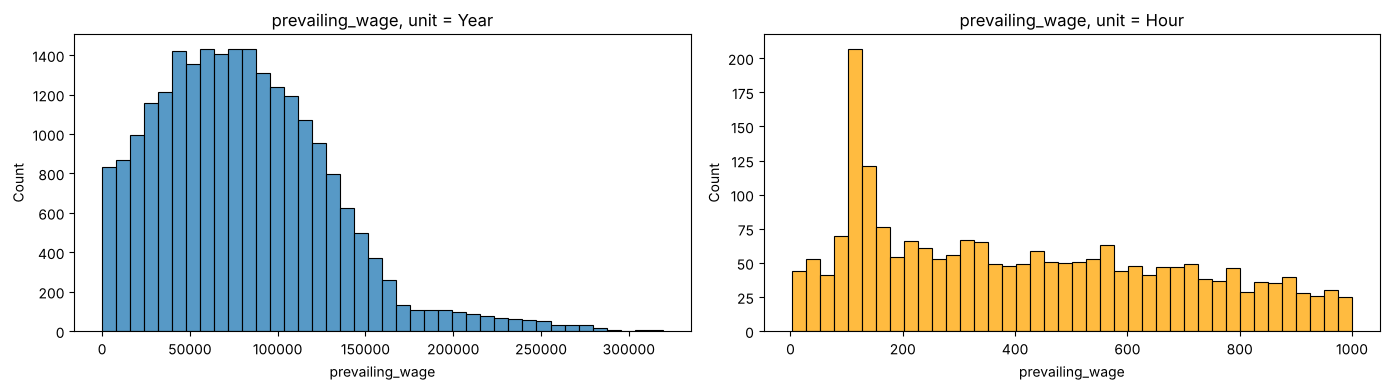

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df[df["unit_of_wage"] == "Year"], x="prevailing_wage", ax=axs[0], bins=40)
axs[0].set_title("prevailing_wage, unit = Year")
sns.histplot(df[df["unit_of_wage"] == "Hour"], x="prevailing_wage", ax=axs[1], bins=40, color="orange")
axs[1].set_title("prevailing_wage, unit = Hour")
plt.tight_layout()
plt.show()

In [14]:
def labeled_barplot(data, feature, perc=False, n=None):
    """Barplot with counts (or percentages) on top of each bar."""
    total = len(data[feature])
    count = data[feature].nunique()
    plt.figure(figsize=((count if n is None else n) + 2, 4))
    plt.xticks(rotation=45, ha="right", fontsize=12)
    ax = sns.countplot(
        data=data, x=feature, hue=feature, palette="Paired", legend=False,
        order=data[feature].value_counts().index[:n],
    )
    for p in ax.patches:
        label = "{:.1f}%".format(100 * p.get_height() / total) if perc else int(p.get_height())
        ax.annotate(label, (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", size=11)
    plt.show()

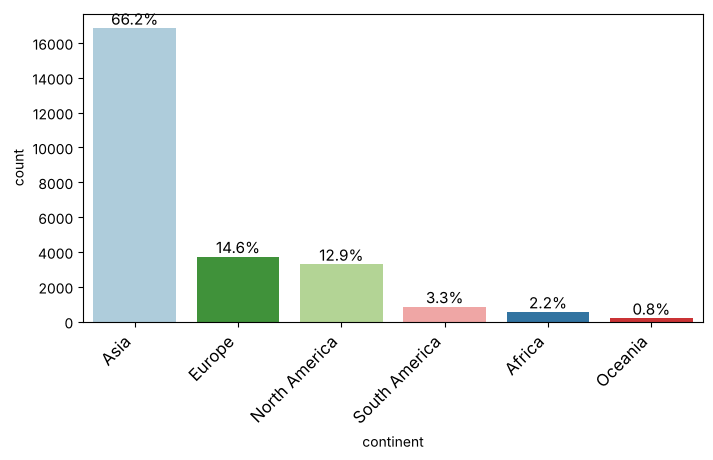

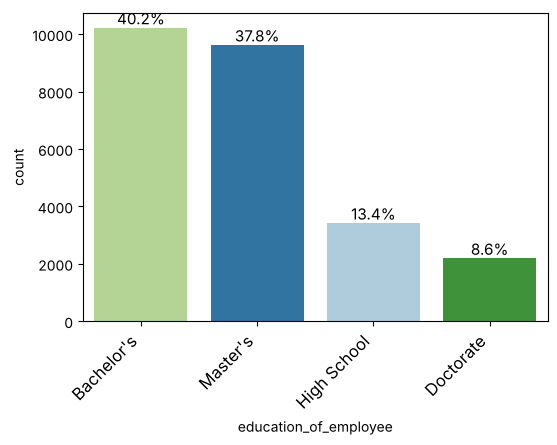

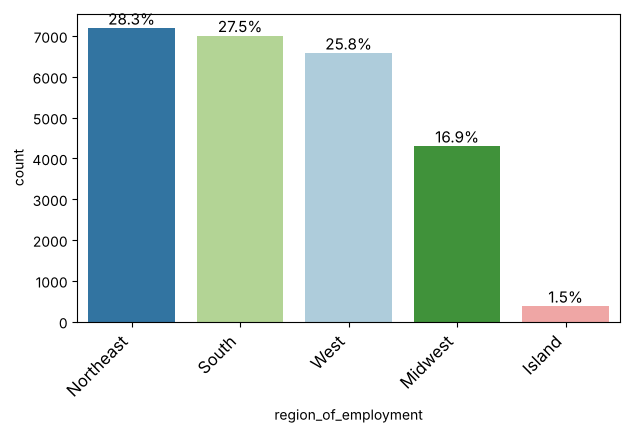

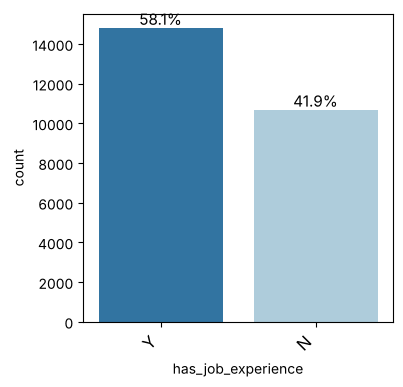

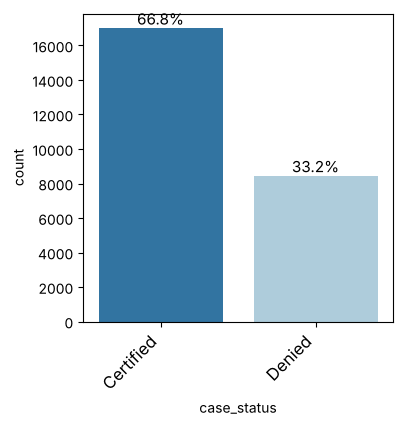

In [15]:
for col in ["continent", "education_of_employee", "region_of_employment", "has_job_experience", "case_status"]:
    labeled_barplot(df, col, perc=True)

- **Education:** Bachelor's (40%) and Master's (38%) make up the large majority of applicants.
- **Region:** few applicants are going to the Island region (1.5%), and the Midwest is the smallest of the four main regions (17%).
- **Job experience:** 58% of applicants have experience and 42% do not, so about 39% more applicants have experience than not.
- **Case status:** 67% of cases are certified, about twice as many as denied.

### Bivariate Analysis

In [16]:
def stacked_barplot(data, predictor, target="case_status"):
    """Counts table, plus a stacked bar of the case-status share within each predictor level."""
    counts = pd.crosstab(data[predictor], data[target], margins=True)
    share = pd.crosstab(data[predictor], data[target], normalize="index").sort_values("Certified", ascending=False)
    print(counts.join((share["Certified"] * 100).round(1).rename("% certified")))
    print("-" * 80)
    share[["Certified", "Denied"]].plot(kind="bar", stacked=True, figsize=(max(5, len(share) + 3), 4), color=["tab:green", "tab:red"])
    plt.ylabel("share of cases")
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1), title=target)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

#### Does higher education increase the chance of certification?

                       Certified  Denied    All  % certified
education_of_employee                                       
Bachelor's                  6362    3858  10220       62.300
Doctorate                   1910     279   2189       87.300
High School                 1164    2252   3416       34.100
Master's                    7565    2057   9622       78.600
All                        17001    8446  25447          NaN
--------------------------------------------------------------------------------


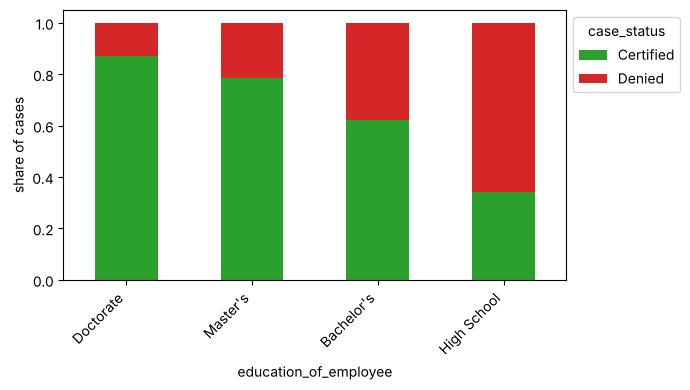

In [17]:
stacked_barplot(df, "education_of_employee")

Yes, strongly. The certification rate rises from 34% (High School) to 62% (Bachelor's), 79% (Master's) and 87% (Doctorate).

#### How does visa status vary across continents?

               Certified  Denied    All  % certified
continent                                           
Africa               396     154    550       72.000
Asia               11001    5839  16840       65.300
Europe              2953     774   3727       79.200
North America       2037    1250   3287       62.000
Oceania              122      70    192       63.500
South America        492     359    851       57.800
All                17001    8446  25447          NaN
--------------------------------------------------------------------------------


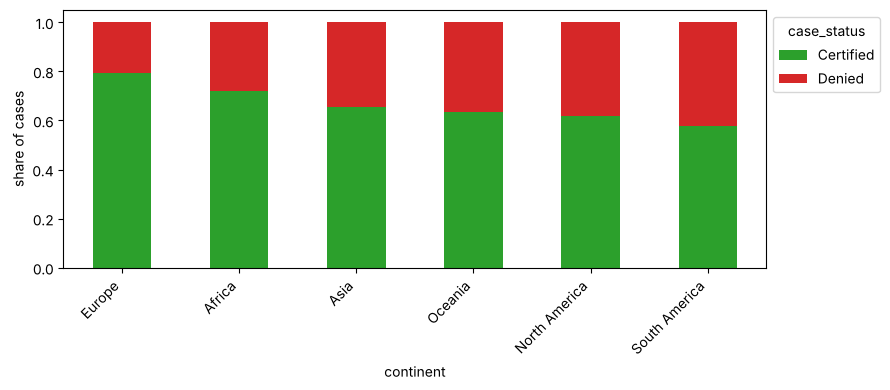

In [18]:
stacked_barplot(df, "continent")

Europe has the highest certification rate (79%), followed by Africa (72%). Asia (65%), Oceania (64%), North America (62%) and South America (58%) are lower. Africa, Oceania and South America have few cases, so their rates are less reliable.

#### Does prior work experience influence certification?

                    Certified  Denied    All  % certified
has_job_experience                                       
N                        5986    4675  10661       56.100
Y                       11015    3771  14786       74.500
All                     17001    8446  25447          NaN
--------------------------------------------------------------------------------


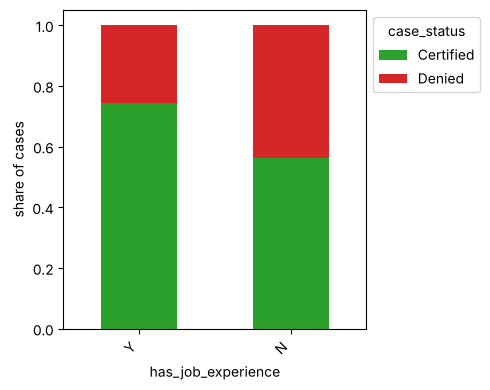

In [19]:
stacked_barplot(df, "has_job_experience")

Yes. 75% of applicants with experience are certified versus 56% without (about 1.3 times as likely, not twice).

#### Does certification vary by region of employment?

                      Certified  Denied    All  % certified
region_of_employment                                       
Island                      226     149    375       60.300
Midwest                    3246    1053   4299       75.500
Northeast                  4524    2665   7189       62.900
South                      4908    2098   7006       70.100
West                       4097    2481   6578       62.300
All                       17001    8446  25447          NaN
--------------------------------------------------------------------------------


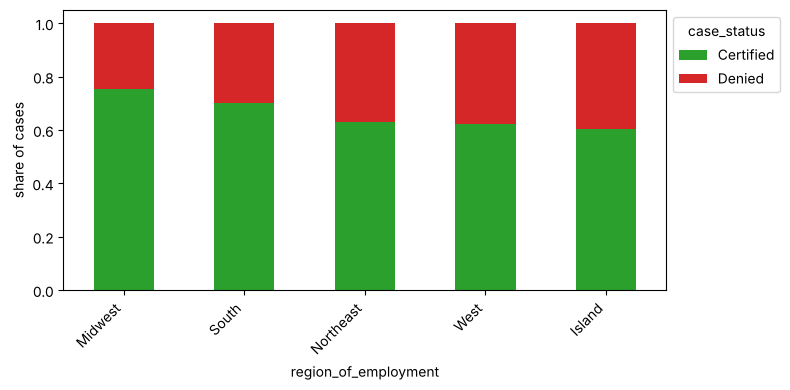

In [20]:
stacked_barplot(df, "region_of_employment")

The Midwest (76%) and South (70%) have the highest certification rates. The Northeast (63%), West (62%) and Island (60%) are lower.

#### Is the prevailing wage consistent across regions?

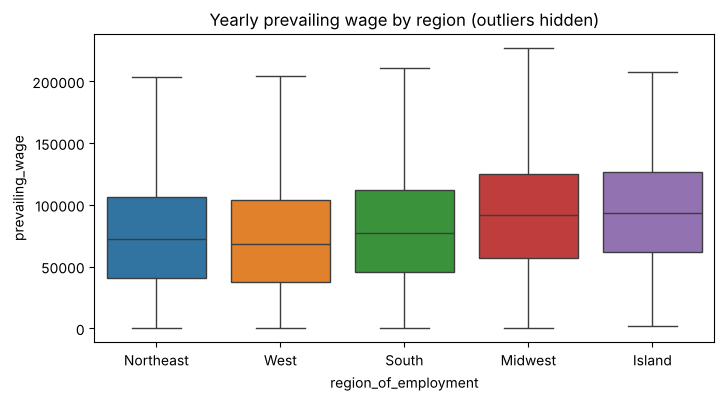

region_of_employment
Island      93528.000
Midwest     91357.000
Northeast   72130.000
South       76956.000
West        68485.000
Name: prevailing_wage, dtype: float64


In [21]:
yearly = df[df["unit_of_wage"] == "Year"]
plt.figure(figsize=(8, 4))
sns.boxplot(data=yearly, x="region_of_employment", y="prevailing_wage", hue="region_of_employment", legend=False, showfliers=False)
plt.title("Yearly prevailing wage by region (outliers hidden)")
plt.show()
print(yearly.groupby("region_of_employment")["prevailing_wage"].median().round(0))

Median yearly prevailing wages differ between regions: the Island (about $94k) and Midwest (about $91k) are the highest, followed by the South (about $77k), Northeast (about $72k) and West (about $68k). All regions overlap heavily, and the spread within a region is much larger than these differences.

#### Does certification vary with the prevailing wage?

Yearly-unit rows only - % certified by wage quintile:
wage_quintile
(99.999, 36974.314]       72.200
(36974.314, 63455.13]     69.800
(63455.13, 89216.966]     69.700
(89216.966, 119867.686]   68.600
(119867.686, 319210.27]   69.100
Name: case_status, dtype: float64


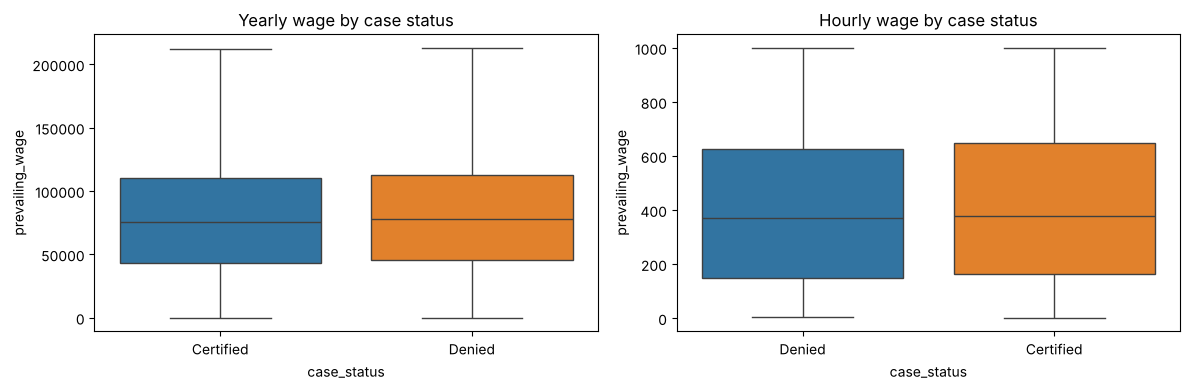

In [22]:
yearly = df[df["unit_of_wage"] == "Year"].copy()
yearly["wage_quintile"] = pd.qcut(yearly["prevailing_wage"], 5)
print("Yearly-unit rows only - % certified by wage quintile:")
print((yearly.groupby("wage_quintile", observed=True)["case_status"].apply(lambda s: (s == "Certified").mean() * 100)).round(1))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=yearly, x="case_status", y="prevailing_wage", hue="case_status", legend=False, ax=axs[0], showfliers=False)
axs[0].set_title("Yearly wage by case status")
hourly = df[df["unit_of_wage"] == "Hour"]
sns.boxplot(data=hourly, x="case_status", y="prevailing_wage", hue="case_status", legend=False, ax=axs[1], showfliers=False)
axs[1].set_title("Hourly wage by case status")
plt.tight_layout()
plt.show()

Once the unit is held fixed, the prevailing wage has **little relationship** with certification: among yearly wages the certified share is 69-72% in every quintile. The earlier impression that "denied cases cluster at very low wages" comes from the hourly-unit rows (see next section), which have small numbers and are mostly denied. So a higher prevailing wage is not by itself a sign of approval.

#### Does the unit of wage matter?

              Certified  Denied    All  % certified
unit_of_wage                                       
Hour                747    1406   2153       34.700
Month                55      34     89       61.800
Week                169     103    272       62.100
Year              16030    6903  22933       69.900
All               17001    8446  25447          NaN
--------------------------------------------------------------------------------


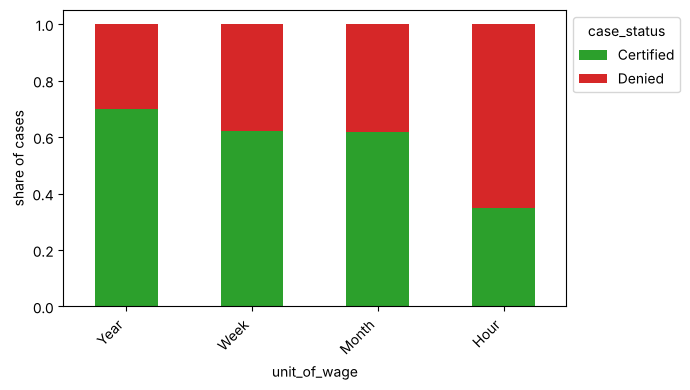

In [23]:
stacked_barplot(df, "unit_of_wage")

Yes. Only 35% of the hourly cases are certified, versus 70% of yearly cases. Weekly and monthly cases (62% each) are few.

#### Other features

                    Certified  Denied    All  % certified
full_time_position                                       
N                        1855     851   2706       68.600
Y                       15146    7595  22741       66.600
All                     17001    8446  25447          NaN
--------------------------------------------------------------------------------


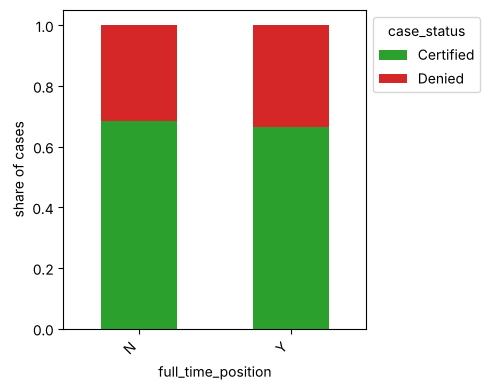

                       Certified  Denied    All  % certified
requires_job_training                                       
N                          15000    7498  22498       66.700
Y                           2001     948   2949       67.900
All                        17001    8446  25447          NaN
--------------------------------------------------------------------------------


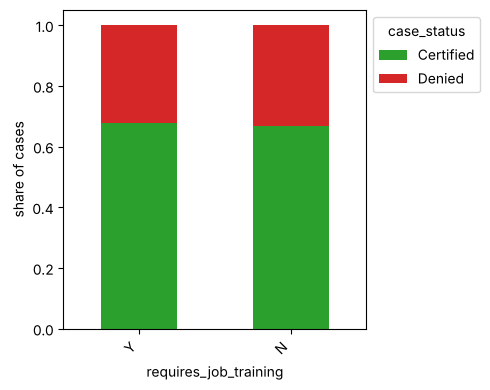

no_of_employees
(11.999, 819.0]      65.400
(819.0, 1670.0]      66.100
(1670.0, 2600.0]     65.600
(2600.0, 3901.0]     67.000
(3901.0, 602069.0]   69.900
Name: % certified by company-size quintile, dtype: float64
yr_of_estab
(1799, 1950]   66.200
(1950, 1980]   66.500
(1980, 2000]   65.500
(2000, 2016]   68.300
Name: % certified by year established, dtype: float64


In [24]:
for col in ["full_time_position", "requires_job_training"]:
    stacked_barplot(df, col)

# company size and age
print((df.groupby(pd.qcut(df["no_of_employees"], 5), observed=True)["case_status"].apply(lambda s: (s == "Certified").mean() * 100)).round(1).rename("% certified by company-size quintile"))
print((df.groupby(pd.cut(df["yr_of_estab"], [1799, 1950, 1980, 2000, 2016]), observed=True)["case_status"].apply(lambda s: (s == "Certified").mean() * 100)).round(1).rename("% certified by year established"))

Full-time status, job-training requirement, company size and company age have very small effects on the certification rate (all within a few percentage points).

#### Education and experience together

In [25]:
pivot = df.assign(y=(df["case_status"] == "Certified").astype(int)).pivot_table(
    index="education_of_employee", columns="has_job_experience", values="y", aggfunc="mean")
(pivot * 100).round(1)

has_job_experience,N,Y
education_of_employee,,
Bachelor's,51.300,70.300
Doctorate,80.100,92.600
High School,31.700,35.700
Master's,64.300,88.800


Experience helps at every education level, most of all for Master's holders (64% to 89%). An applicant with a High School education is unlikely to be certified with or without experience (32% and 36%).

## Data Preprocessing

### Outlier check

`no_of_employees` and `prevailing_wage` have long right tails, but the large values are plausible (companies up to about 600,000 employees, yearly wages up to about $320,000), and tree-based models are not sensitive to extreme values. No outliers are removed. The only rows removed from the data are the 33 with an invalid (negative) number of employees.

### Data preparation for modelling

- The target is `case_status` (1 = Certified, 0 = Denied).
- `has_job_experience`, `requires_job_training` and `full_time_position` become 0/1.
- `education_of_employee` is ordinal (High School < Bachelor's < Master's < Doctorate) and is encoded as 0-3.
- `continent`, `region_of_employment` and `unit_of_wage` are one-hot encoded.
- The encoding is deterministic (it uses no information from the target or other rows), so it is done before the split. This guarantees that train, validation and test have identical columns.
- The data is split 60% train / 20% validation / 20% test, stratified on the target.

In [26]:
data1 = df.copy()

yes_no = {"Y": 1, "N": 0}
for col in ["has_job_experience", "requires_job_training", "full_time_position"]:
    data1[col] = data1[col].map(yes_no)

data1["education_of_employee"] = data1["education_of_employee"].map(
    {"High School": 0, "Bachelor's": 1, "Master's": 2, "Doctorate": 3}
)

y = data1["case_status"].map({"Denied": 0, "Certified": 1})
X = data1.drop(columns="case_status")
X = pd.get_dummies(X, columns=["continent", "region_of_employment", "unit_of_wage"], drop_first=True, dtype=int)
X.columns = [c.replace(" ", "_") for c in X.columns]

print(X.shape)
print(X.isna().sum().sum(), "missing values")
X.head()

(25447, 19)
0 missing values


,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,prevailing_wage,full_time_position,continent_Asia,continent_Europe,continent_North_America,continent_Oceania,continent_South_America,region_of_employment_Midwest,region_of_employment_Northeast,region_of_employment_South,region_of_employment_West,unit_of_wage_Month,unit_of_wage_Week,unit_of_wage_Year
0,0,0,0,14513,2007,592.203,1,1,0,0,0,0,0,0,0,1,0,0,0
1,2,1,0,2412,2002,83425.650,1,1,0,0,0,0,0,1,0,0,0,0,1
2,1,0,1,44444,2008,122996.860,1,1,0,0,0,0,0,0,0,1,0,0,1
3,1,0,0,98,1897,83434.030,1,1,0,0,0,0,0,0,0,1,0,0,1
4,2,1,0,1082,2005,149907.390,1,0,0,0,0,0,0,0,1,0,0,0,1


In [27]:
# 60% train / 20% validation / 20% test
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=RANDOM_STATE, stratify=y_temp)

print("Train / validation / test rows:", X_train.shape[0], X_val.shape[0], X_test.shape[0])
print("Share certified:", y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

Train / validation / test rows: 15267 5090 5090
Share certified: 0.668 0.668 0.668


The three sets have the same share of certified cases (66.8%), so the stratified split worked.

## Model Building

### Model Evaluation Criterion

The target is 1 = **Certified**, 0 = **Denied**. 67% of cases are certified, so:

- **Accuracy, recall and F1 on the Certified class are easy to inflate.** A "model" that certifies every case has accuracy 66.8%, recall 100%, precision 66.8% and F1 0.80. Any real model has to be compared with this reference.
- **Two kinds of mistakes matter.** Certifying a case that should be denied (a false positive) wastes review effort and can let through ineligible applications. Denying a case that should be certified (a false negative) turns away a qualified applicant. OFLC wants a *shortlist of cases with a higher chance of approval*, so precision and recall both matter.
- **ROC-AUC** measures how well the model ranks certified cases above denied ones, regardless of the cut-off. It cannot be gamed by predicting one class, so it is the **primary metric for tuning and model selection**. Accuracy, recall, precision and F1 are reported alongside it.


In [28]:
def model_performance_classification_sklearn(model, predictors, target):
    """Accuracy, recall, precision, F1 (for the Certified class) and ROC-AUC of a fitted model."""
    pred = model.predict(predictors)
    proba = model.predict_proba(predictors)[:, 1]
    return pd.DataFrame(
        {
            "Accuracy": accuracy_score(target, pred),
            "Recall": recall_score(target, pred),
            "Precision": precision_score(target, pred),
            "F1": f1_score(target, pred),
            "ROC-AUC": roc_auc_score(target, proba),
        },
        index=[0],
    )

In [29]:
# Reference point: certify every case
all_certified = pd.DataFrame(
    {"Accuracy": y_val.mean(), "Recall": 1.0, "Precision": y_val.mean(),
     "F1": 2 * y_val.mean() / (1 + y_val.mean()), "ROC-AUC": 0.5},
    index=["Baseline: certify everyone"],
)
all_certified

,Accuracy,Recall,Precision,F1,ROC-AUC
Baseline: certify everyone,0.668,1.000,0.668,0.801,0.500


### Baseline models on the original, oversampled (SMOTE) and undersampled training data

Seven model types are fitted on each version of the training data and scored on the **validation** set. Resampling is applied to the training data only. (SMOTE creates synthetic rows by interpolating between neighbours, which gives fractional values for the 0/1 columns; this is acceptable here but only an approximation.)

In [30]:
def make_models():
    return {
        "Bagging": BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE), random_state=RANDOM_STATE),
        "Random forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        "GBM": GradientBoostingClassifier(random_state=RANDOM_STATE),
        "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE),
        "Decision tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=2),
        "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    }

X_train_over, y_train_over = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train, y_train)
X_train_un, y_train_un = RandomUnderSampler(random_state=RANDOM_STATE).fit_resample(X_train, y_train)

print(f"Original:     certified {int(y_train.sum())}, denied {int((1 - y_train).sum())}")
print(f"Oversampled:  certified {int(y_train_over.sum())}, denied {int((1 - y_train_over).sum())}")
print(f"Undersampled: certified {int(y_train_un.sum())}, denied {int((1 - y_train_un).sum())}")

Original:     certified 10199, denied 5068
Oversampled:  certified 10199, denied 10199
Undersampled: certified 5068, denied 5068


In [31]:
train_sets = {
    "Original": (X_train, y_train),
    "Oversampled": (X_train_over, y_train_over),
    "Undersampled": (X_train_un, y_train_un),
}

rows = []
for variant, (Xt, yt) in train_sets.items():
    for name, model in make_models().items():
        model.fit(Xt, yt)
        val_perf = model_performance_classification_sklearn(model, X_val, y_val).iloc[0]
        rows.append({
            "Training data": variant, "Model": name,
            "Train ROC-AUC": roc_auc_score(yt, model.predict_proba(Xt)[:, 1]),
            "Val ROC-AUC": val_perf["ROC-AUC"], "Val F1": val_perf["F1"],
            "Val recall": val_perf["Recall"], "Val precision": val_perf["Precision"],
            "Val accuracy": val_perf["Accuracy"],
        })
baseline_results = pd.DataFrame(rows)
baseline_results["Train - Val AUC"] = baseline_results["Train ROC-AUC"] - baseline_results["Val ROC-AUC"]
baseline_results.pivot(index="Model", columns="Training data", values="Val ROC-AUC")

Training data,Original,Oversampled,Undersampled
Model,,,
AdaBoost,0.766,0.755,0.764
Bagging,0.730,0.723,0.733
Decision tree,0.610,0.621,0.621
GBM,0.775,0.771,0.773
Logistic regression,0.762,0.751,0.763
Random forest,0.754,0.755,0.753
XGBoost,0.761,0.760,0.753


In [32]:
baseline_results.sort_values("Val ROC-AUC", ascending=False).head(10).round(3)

,Training data,Model,Train ROC-AUC,Val ROC-AUC,Val F1,Val recall,Val precision,Val accuracy,Train - Val AUC
2,Original,GBM,0.797,0.775,0.827,0.881,0.780,0.754,0.022
16,Undersampled,GBM,0.802,0.773,0.770,0.728,0.817,0.710,0.028
9,Oversampled,GBM,0.885,0.771,0.809,0.826,0.793,0.739,0.114
3,Original,AdaBoost,0.772,0.766,0.824,0.899,0.760,0.743,0.006
17,Undersampled,AdaBoost,0.769,0.764,0.761,0.716,0.811,0.699,0.005
20,Undersampled,Logistic regression,0.765,0.763,0.752,0.694,0.821,0.694,0.002
6,Original,Logistic regression,0.766,0.762,0.821,0.892,0.760,0.740,0.003
5,Original,XGBoost,0.930,0.761,0.811,0.857,0.769,0.732,0.169
12,Oversampled,XGBoost,0.956,0.760,0.803,0.828,0.780,0.729,0.196
10,Oversampled,AdaBoost,0.862,0.755,0.786,0.788,0.785,0.714,0.107


**Observations (validation ROC-AUC)**

- The best baseline is Gradient Boosting on the original data (0.775). AdaBoost (0.766), logistic regression (0.762) and XGBoost (0.761) are close behind. A single decision tree is much worse (0.61).
- Resampling (SMOTE or undersampling) did **not** improve the ranking quality: for the best models the change is within about 0.01, and it lowered Gradient Boosting from 0.775 to 0.771-0.773. It mainly shifts the balance between recall and precision.
- Decision trees, bagging, random forest and XGBoost fit the training data much better than the validation data (train-validation AUC gap of 0.17-0.20 for XGBoost on the original data, 0.11 for Gradient Boosting on oversampled data), a sign of overfitting. Gradient Boosting on the original data and AdaBoost have small gaps.
- The simplest model (logistic regression) is almost as good as the best, which means the signal in these ten features is modest (AUC around 0.77).


### Hyperparameter tuning

The three boosting models (AdaBoost, Gradient Boosting, XGBoost) are tuned with randomised search, scoring **ROC-AUC with 3-fold cross-validation on the training data**. The resampling method is itself a searched hyperparameter (`passthrough` = no resampling), and it sits inside an `imblearn` pipeline. This way resampling is applied only to the training part of each fold, and the validation part of each fold stays untouched real data. Resampling the whole training set first would leak synthetic copies of validation rows into the training folds and inflate the CV score.

In [33]:
samplers = ["passthrough", SMOTE(random_state=RANDOM_STATE), RandomUnderSampler(random_state=RANDOM_STATE)]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def tune(name, model, param_distributions, n_iter=12):
    pipe = ImbPipeline([("sampler", "passthrough"), ("model", model)])
    params = {"sampler": samplers, **{f"model__{k}": v for k, v in param_distributions.items()}}
    search = RandomizedSearchCV(
        pipe, params, n_iter=n_iter, scoring="roc_auc", cv=cv, random_state=RANDOM_STATE, n_jobs=2,
    )
    search.fit(X_train, y_train)
    sampler_name = type(search.best_params_["sampler"]).__name__ if search.best_params_["sampler"] != "passthrough" else "none"
    print(f"{name}: best CV ROC-AUC = {search.best_score_:.4f}")
    print("  sampler:", sampler_name)
    print("  ", {k: v for k, v in search.best_params_.items() if k != "sampler"})
    return search

In [34]:
ada_search = tune(
    "AdaBoost",
    AdaBoostClassifier(random_state=RANDOM_STATE),
    {
        "n_estimators": [50, 90, 150, 200],
        "learning_rate": [0.05, 0.1, 0.2, 0.5, 1.0],
        "estimator": [DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE) for d in (1, 2, 3, 4)],
    },
)

AdaBoost: best CV ROC-AUC = 0.7772
  sampler: RandomUnderSampler
   {'model__n_estimators': 50, 'model__learning_rate': 0.1, 'model__estimator': DecisionTreeClassifier(max_depth=4, random_state=1)}


In [35]:
gbm_search = tune(
    "Gradient Boosting",
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    {
        "n_estimators": [100, 150, 200],
        "learning_rate": [0.02, 0.05, 0.1, 0.2],
        "max_depth": [2, 3, 4, 5],
        "subsample": [0.8, 0.9, 1.0],
        "max_features": [0.5, 0.7, 1.0],
    },
)

Gradient Boosting: best CV ROC-AUC = 0.7797
  sampler: none
   {'model__subsample': 0.9, 'model__n_estimators': 200, 'model__max_features': 0.7, 'model__max_depth': 3, 'model__learning_rate': 0.02}


In [36]:
xgb_search = tune(
    "XGBoost",
    XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=1),
    {
        "n_estimators": [100, 150, 200, 300],
        "learning_rate": [0.02, 0.05, 0.1, 0.2],
        "max_depth": [2, 3, 4, 5, 6],
        "subsample": [0.8, 0.9, 1.0],
        "colsample_bytree": [0.5, 0.7, 1.0],
    },
)

XGBoost: best CV ROC-AUC = 0.7814
  sampler: none
   {'model__subsample': 0.8, 'model__n_estimators': 100, 'model__max_depth': 4, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.5}


### Comparing the tuned models on the validation set

Each tuned model was refit on the full training set by the search (with its chosen resampling inside the pipeline). Training performance is on the original (not resampled) training data.

In [37]:
tuned_models = {
    "AdaBoost (tuned)": ada_search.best_estimator_,
    "Gradient Boosting (tuned)": gbm_search.best_estimator_,
    "XGBoost (tuned)": xgb_search.best_estimator_,
}

train_comp = pd.concat([model_performance_classification_sklearn(m, X_train, y_train).T for m in tuned_models.values()], axis=1)
val_comp = pd.concat(
    [model_performance_classification_sklearn(m, X_val, y_val).T for m in tuned_models.values()]
    + [all_certified.T], axis=1,
)
train_comp.columns = list(tuned_models)
val_comp.columns = list(tuned_models) + ["Baseline: certify everyone"]

print("Training performance:")
display(train_comp.round(3))
print("Validation performance:")
display(val_comp.round(3))

Training performance:


,AdaBoost (tuned),Gradient Boosting (tuned),XGBoost (tuned)
Accuracy,0.707,0.751,0.757
Recall,0.704,0.879,0.886
Precision,0.832,0.778,0.780
F1,0.763,0.825,0.830
ROC-AUC,0.787,0.787,0.796


Validation performance:


,AdaBoost (tuned),Gradient Boosting (tuned),XGBoost (tuned),Baseline: certify everyone
Accuracy,0.701,0.750,0.749,0.668
Recall,0.706,0.883,0.884,1.000
Precision,0.821,0.775,0.773,0.668
F1,0.760,0.825,0.825,0.801
ROC-AUC,0.773,0.773,0.776,0.500


**Observations**

- The three tuned models are very close on validation (ROC-AUC 0.773-0.776); the differences are within noise. Gradient Boosting and XGBoost chose no resampling, and AdaBoost chose undersampling.
- Training and validation scores are close (for XGBoost, AUC 0.796 vs 0.776), so overfitting is mild.
- All three beat the "certify everyone" reference on accuracy (about 0.75 vs 0.668) and ROC-AUC (0.77 vs 0.50). On F1 the gain is small (0.825 vs 0.801), and the reference has perfect recall by construction.


### Final model selection and test performance

The final model is the tuned model with the **highest validation ROC-AUC**. The test set is used only once, for this model.

In [38]:
best_name = val_comp.drop(columns="Baseline: certify everyone").loc["ROC-AUC"].idxmax()
final_model = tuned_models[best_name]
print("Final model:", best_name)

test_perf = model_performance_classification_sklearn(final_model, X_test, y_test)
test_baseline = pd.DataFrame(
    {"Accuracy": y_test.mean(), "Recall": 1.0, "Precision": y_test.mean(),
     "F1": 2 * y_test.mean() / (1 + y_test.mean()), "ROC-AUC": 0.5},
    index=["Baseline: certify everyone"],
)
pd.concat([test_perf.rename(index={0: best_name}), test_baseline]).round(3)

Final model: XGBoost (tuned)


,Accuracy,Recall,Precision,F1,ROC-AUC
XGBoost (tuned),0.749,0.874,0.778,0.823,0.779
Baseline: certify everyone,0.668,1.000,0.668,0.801,0.500


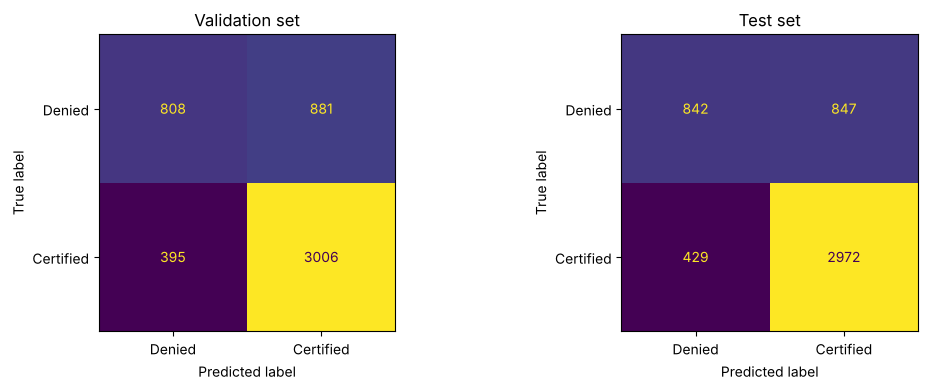

In [39]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_estimator(final_model, X_val, y_val, display_labels=["Denied", "Certified"], ax=axs[0], colorbar=False)
axs[0].set_title("Validation set")
ConfusionMatrixDisplay.from_estimator(final_model, X_test, y_test, display_labels=["Denied", "Certified"], ax=axs[1], colorbar=False)
axs[1].set_title("Test set")
plt.tight_layout()
plt.show()

In [40]:
tn, fp, fn, tp = confusion_matrix(y_test, final_model.predict(X_test)).ravel()
print(f"Test set: {tp} certified cases correctly certified, {fn} wrongly denied")
print(f"          {tn} denied cases correctly denied, {fp} wrongly certified ({fp / (tn + fp):.0%} of denied cases)")

Test set: 2972 certified cases correctly certified, 429 wrongly denied
          842 denied cases correctly denied, 847 wrongly certified (50% of denied cases)


**Test-set results.** The final model reaches accuracy 74.9% and ROC-AUC 0.78, against 66.8% accuracy and 0.50 AUC for certifying everyone. Recall for certified cases is 87%, precision 78% and F1 0.82 (reference: 0.80). These are almost identical to the validation results, so the choice of model did not overfit the validation set.

**What it gets wrong.** The confusion matrix shows the model correctly certifies most certified cases but also certifies about half of the cases that were actually denied (about 850 of 1,690 denied cases in the test set). It is therefore best used to **rank and prioritise** cases, not to make decisions automatically.


### Which features matter?

Permutation importance on the validation set: how much the ROC-AUC drops when one feature's values are shuffled. This is more reliable than the built-in importances of boosted trees, which favour numeric features with many distinct values.

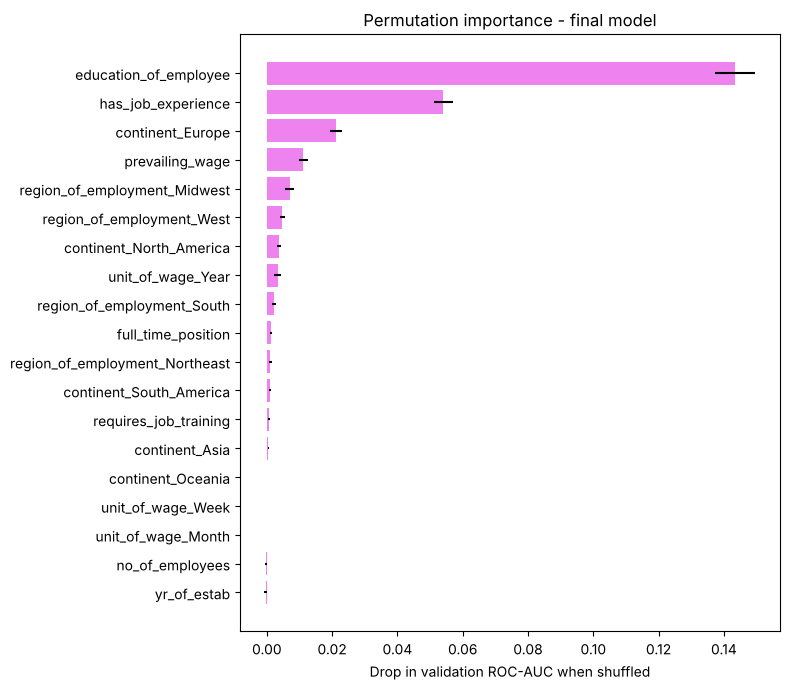

education_of_employee          0.143
has_job_experience             0.054
continent_Europe               0.021
prevailing_wage                0.011
region_of_employment_Midwest   0.007
region_of_employment_West      0.005
continent_North_America        0.004
unit_of_wage_Year              0.003
region_of_employment_South     0.002
full_time_position             0.001
dtype: float64

In [41]:
perm = permutation_importance(
    final_model, X_val, y_val, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=2,
)
importances = pd.Series(perm.importances_mean, index=X_val.columns).sort_values()
std = pd.Series(perm.importances_std, index=X_val.columns)[importances.index]

plt.figure(figsize=(8, 7))
plt.barh(importances.index, importances.values, xerr=std.values, color="violet")
plt.xlabel("Drop in validation ROC-AUC when shuffled")
plt.title("Permutation importance - final model")
plt.tight_layout()
plt.show()
importances.sort_values(ascending=False).head(10).round(4)

- **Education** is by far the most important feature (shuffling it lowers AUC by about 0.14), followed by **job experience** (about 0.05).
- Every other feature is worth about 0.02 or less: continent (Europe), the prevailing wage (largely because small values identify the hourly cases), and region (Midwest, West). Company size, company age, full-time status and job training contribute almost nothing.
- This matches the EDA: education and experience are the strongest relationships with certification.


## Actionable Insights and Recommendations

Education and job experience drive the model, and the EDA agrees. The rates below are certification rates in the full dataset (overall 67%).

**Profile most likely to be certified**

1. **Advanced education:** Doctorate 87% and Master's 79%, versus 62% for Bachelor's and 34% for High School.
2. **Prior job experience:** 75% versus 56% without. Experience helps most at the Master's level (64% to 89%); Doctorate holders with experience are certified 93% of the time.
3. **Yearly-wage positions:** 70% certified, versus 35% for hourly-wage positions.
4. **Employer in the Midwest (76%) or South (70%)**, compared with 60-63% in the Northeast, West and Island regions.
5. **Applicants from Europe (79%)**; the other continents range from 58% to 72%.

**Profile that needs closer review**

- **High School education:** only 34% are certified, and experience barely changes that (32% without, 36% with).
- **Bachelor's degree without experience:** 51%.
- **Hourly-wage positions:** 35%.

**Things that do not matter much:** full-time status, whether job training is required, company size, company age, and (within the same wage unit) the level of the prevailing wage. A high prevailing wage is *not* a sign of approval.

**How to use the model**

- Use the predicted probability to **sort cases for review order** and to fast-track the highest-scoring ones. Do not use it to auto-deny: it flags only about half of the cases that end up denied, and its ROC-AUC (0.78) is moderate.
- **Review fairness before any operational use.** The model, like the EDA, uses continent and region, which can act as a proxy for nationality. An operational model should be checked for disparate impact, and it can probably drop `continent` at little cost (its importance is small).
- Re-train and re-check periodically; policy and applicant mix change over time.

**Data caveats**

- `unit_of_wage` appears unreliable: weekly and monthly "wages" are on a yearly scale (about $80k), so the unit labels should be checked with the data owner.
- The data has no occupation, job title or offered wage, which likely explain part of the unexplained variation. These patterns are associations, not proof that any factor causes approval or denial.
